# Кластеризация недвижимости: поиск групп по характеристикам

Цель исследования — выявить структуру объектов недвижимости на основе сходства характеристик. Группы формируются **без использования фактической стоимости (`SalePrice`) и ценовой категории**. Эти величины привлекаются только после обучения для содержательной оценки найденных кластеров.

Основной метод — K-means (метод k-средних). Число групп определяется по коэффициенту силуэта (*Silhouette Score*) с ограничением на минимальный размер группы. Для представления структуры применяются PCA (анализ главных компонент) и дополнительно t-SNE, для альтернативного сравнения — DBSCAN (кластеризация по плотности).

Исследование выполняется на 1 168 домах из обучающей части исходного набора. Внешняя тестовая выборка не участвует в построении групп.

## 1. Подготовка данных

Используются восемь содержательно интерпретируемых числовых характеристик: общее качество, состояние, суммарная площадь, количество санузлов, вместимость гаража, возраст, площадь участка и отделанная площадь подвала. Категориальные признаки OHE исключены из текущей постановки, чтобы не придавать чрезмерный вес редким категориям.

Числовые пропуски заполнены медианами, для отдельных характеристик ограничены экстремальные значения, затем выполнена стандартизация. Все преобразования обучены только на исследуемой обучающей части, без цен и внешнего теста.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from house_prices_ai.clustering import CLUSTER_FEATURES, FRIENDLY

OUTPUT = ROOT / "outputs" / "clustering"
if not (OUTPUT / "cluster_k_selection.csv").is_file():
    raise FileNotFoundError("Сначала выполните: python main.py clustering --tsne --dbscan")

selection = pd.read_csv(OUTPUT / "cluster_k_selection.csv")
profiles = pd.read_csv(OUTPUT / "cluster_profiles.csv").sort_values("Cluster")
assignments = pd.read_csv(OUTPUT / "cluster_assignments.csv")
features_mean = pd.read_csv(OUTPUT / "cluster_mean_characteristics.csv")
selected_k = int(len(profiles))
best = selection.loc[selection["k"] == selected_k].iloc[0]

print(f"Число объектов: {len(assignments)}")
print(f"Признаков для группировки: {len(CLUSTER_FEATURES)}")
display(pd.DataFrame({
    "Характеристика": [FRIENDLY[name] for name in CLUSTER_FEATURES],
    "Признак": CLUSTER_FEATURES,
}))

Число объектов: 1168
Признаков для группировки: 8


,Характеристика,Признак
0,Общее качество,OverallQual
1,Общее состояние,OverallCond
2,Суммарная площадь,TotalUsefulSF
3,Санузлы (экв.),TotalBathrooms
4,Вместимость гаража,GarageCars
5,Возраст дома,PropertyAgeAtSale
6,Площадь участка,LotArea
7,Отделанный подвал,BsmtFinSF1


## 2. Выбор числа кластеров

Инерция (*inertia*, сумма квадратов расстояний от объектов до центров групп) закономерно уменьшается при увеличении числа кластеров. Поэтому метод «локтя» используется как наглядный ориентир, но не как единственный критерий выбора.

Коэффициент силуэта (*Silhouette Score*) учитывает сходство объектов внутри своей группы и отличие от соседней группы. Чем выше значение, тем чётче геометрическое разделение. Проверены значения `k` от 2 до 8, а число кластеров выбиралось среди вариантов с размером каждой группы не менее 5% выборки.

In [2]:
display(selection.round(4))
print(f"Выбрано k = {selected_k}, коэффициент силуэта = {best['Silhouette']:.4f}")
print(f"Calinski–Harabasz = {best['CalinskiHarabasz']:.1f}, Davies–Bouldin = {best['DaviesBouldin']:.3f}")

,k,Inertia,Silhouette,CalinskiHarabasz,DaviesBouldin,MinClusterSize,MinClusterFraction
0,2,6428.7595,0.2652,528.7444,1.4065,582,0.4983
1,3,5561.4950,0.2114,396.1751,1.5414,208,0.1781
2,4,4993.8348,0.1918,337.9896,1.6711,184,0.1575
3,5,4572.0856,0.1849,303.4576,1.6517,162,0.1387
4,6,4256.3169,0.1726,277.7936,1.5597,135,0.1156
5,7,4028.6333,0.1771,255.3033,1.5623,119,0.1019
6,8,3818.4580,0.1655,239.7987,1.5783,98,0.0839


Выбрано k = 2, коэффициент силуэта = 0.2652
Calinski–Harabasz = 528.7, Davies–Bouldin = 1.407


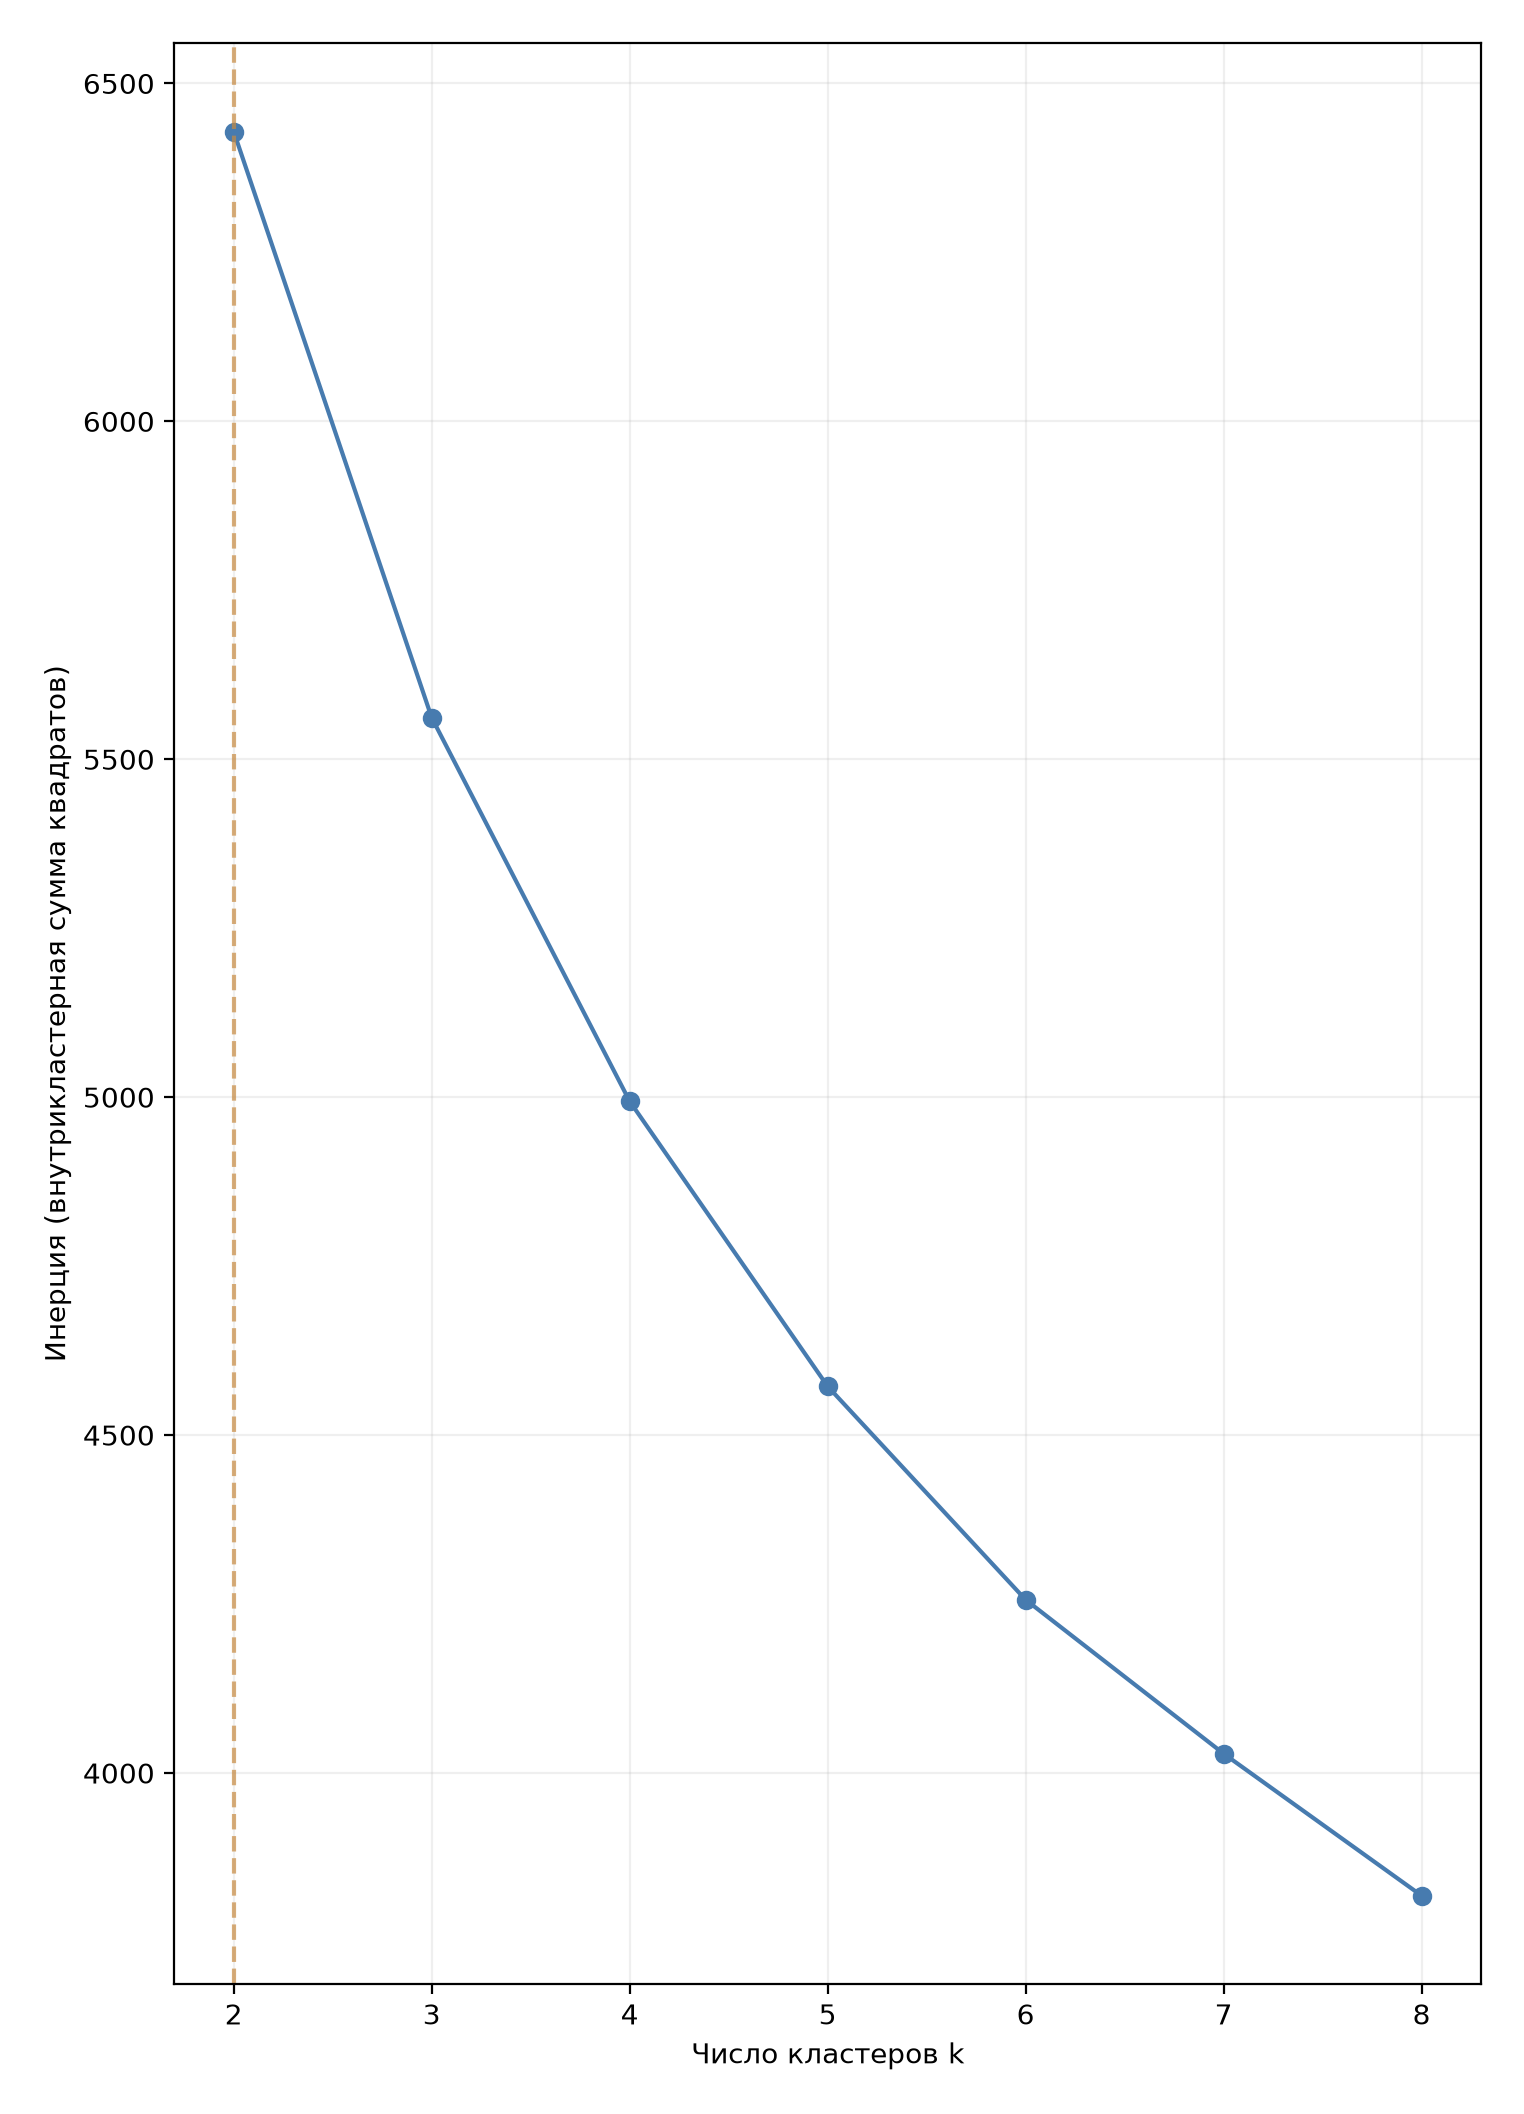

In [3]:
display(Image(filename=str(OUTPUT / "figures" / "6_1_elbow.png"), width=650))

*Рисунок 6.1 — Зависимость инерции K-means от числа кластеров.*

Инерция монотонно снижается по мере увеличения числа центров, что является ожидаемым свойством K-means. Снижение инерции не означает автоматического улучшения содержательной интерпретируемости групп, поэтому выбор числа кластеров дополнительно проверяется по коэффициенту силуэта.

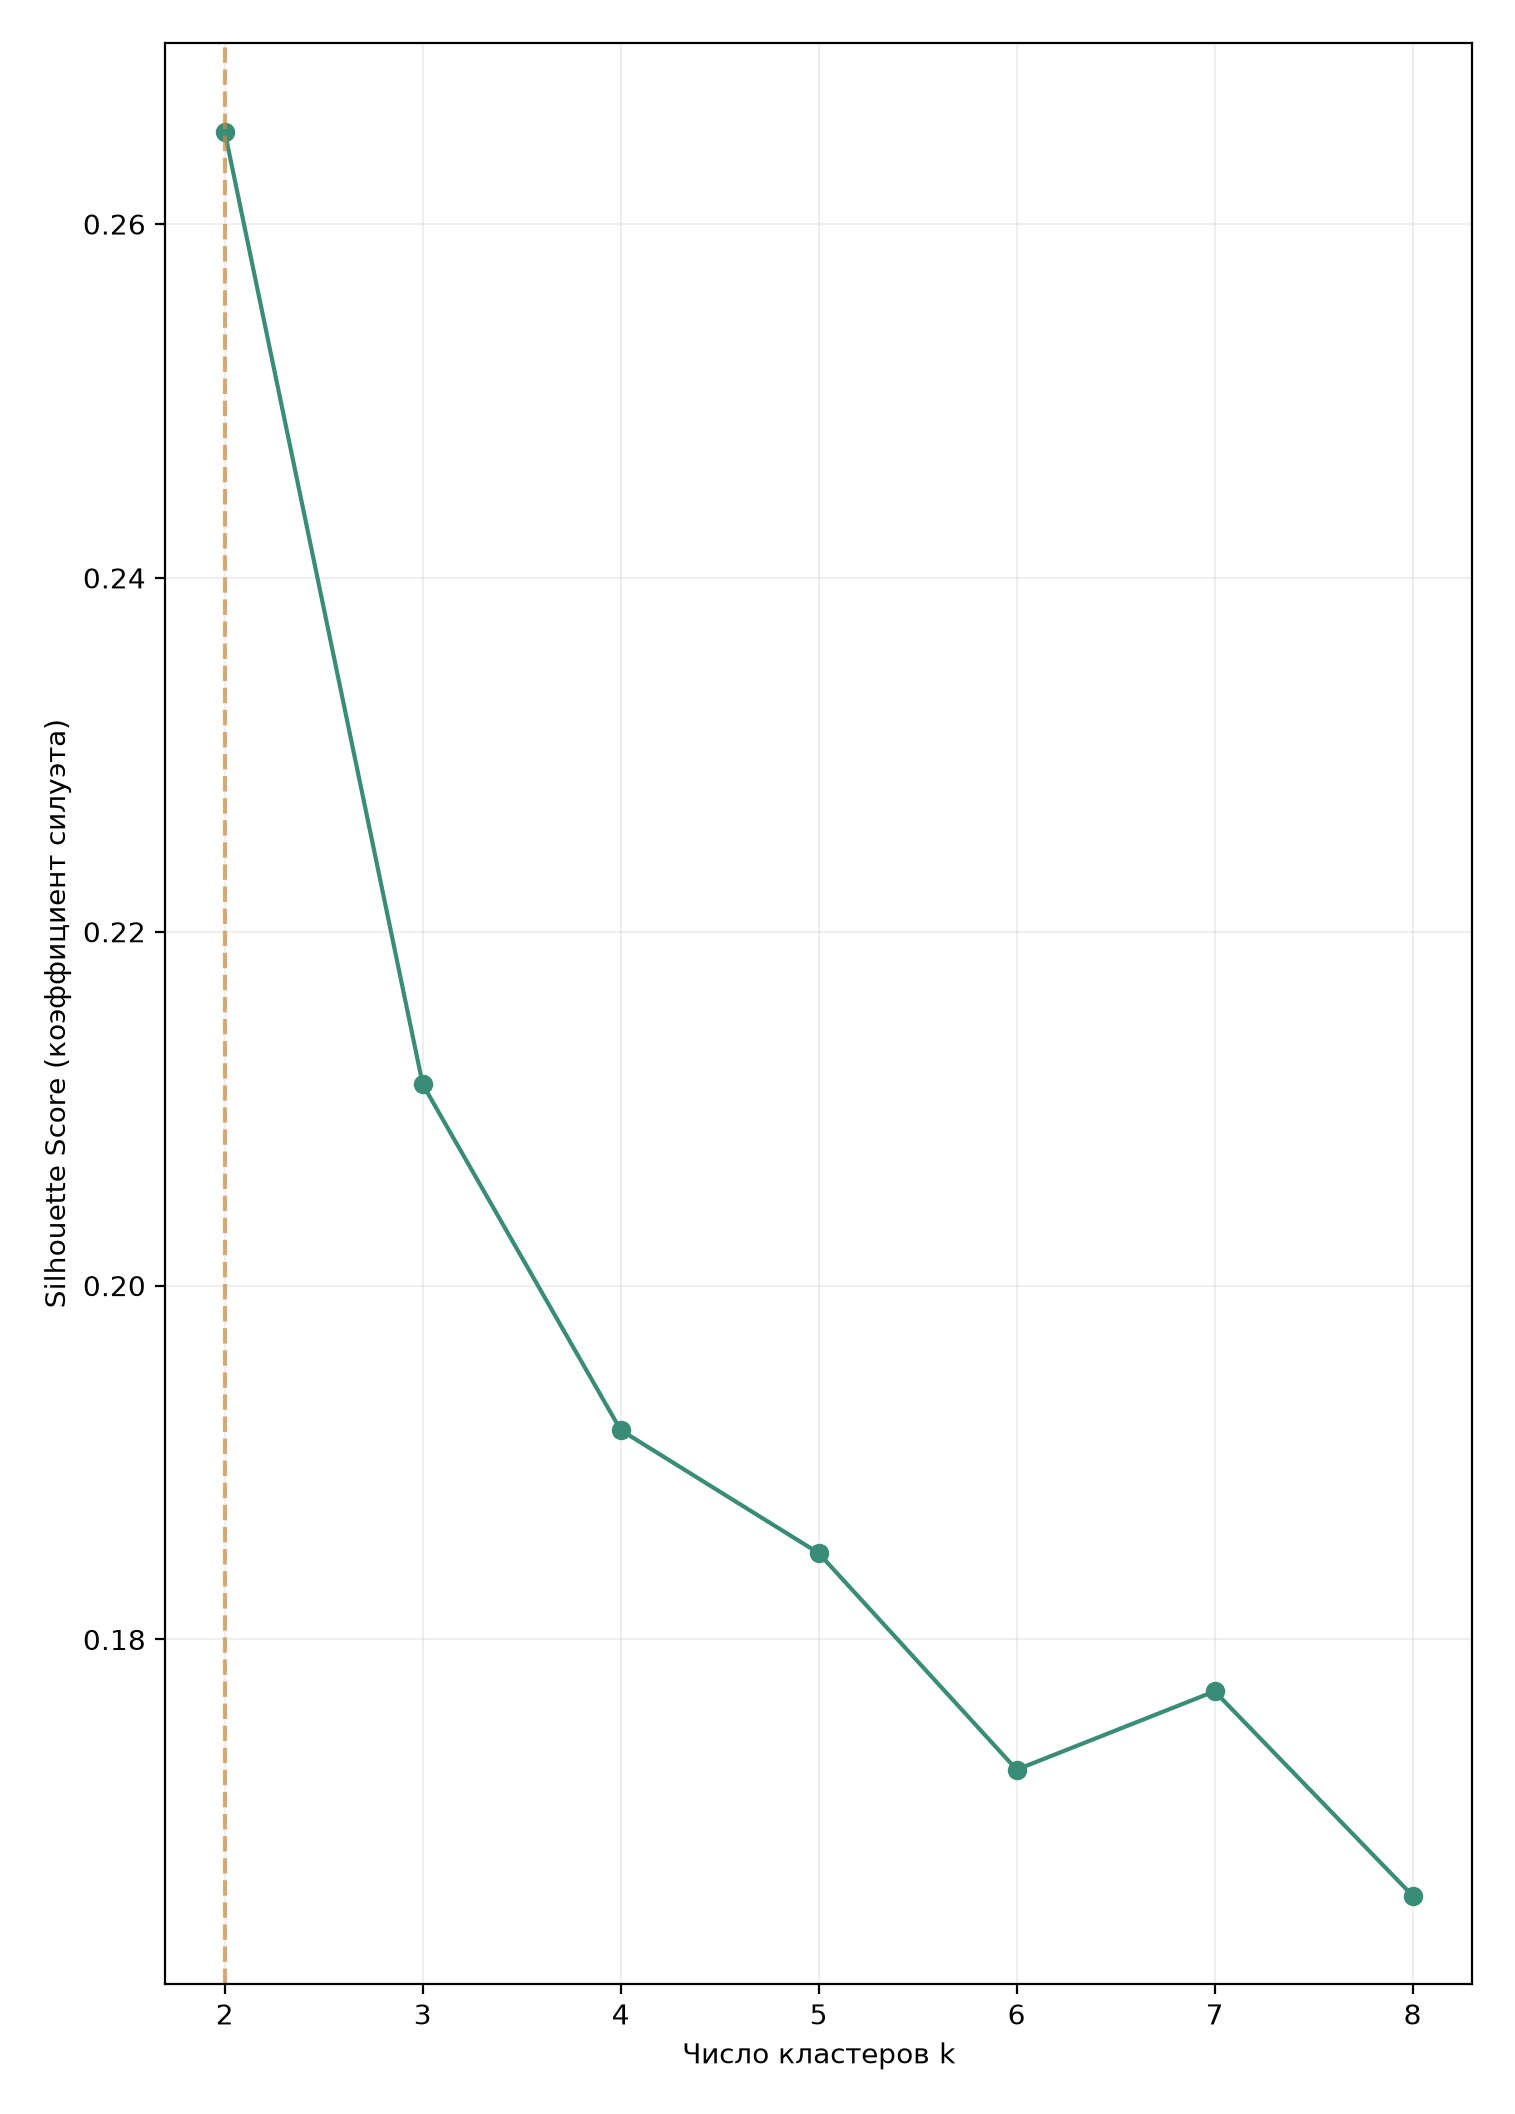

In [4]:
display(Image(filename=str(OUTPUT / "figures" / "6_2_silhouette.png"), width=650))

*Рисунок 6.2 — Коэффициент силуэта при различных значениях k.*

На исследуемых данных максимум коэффициента силуэта составляет **0,2652 при k = 2**. Для других проверенных значений k он ниже. Следовательно, два кластера являются предпочтительным вариантом **среди рассмотренных конфигураций**, хотя само значение силуэта невелико и говорит о перекрытии групп в пространстве признаков.

Таким образом, для дальнейшего описательного анализа принято разделение на два кластера. Оно определяется исключительно характеристиками недвижимости, а не её стоимостью.

## 3. Пространственное представление и профили групп

PCA (анализ главных компонент) переводит исходные восемь стандартизированных характеристик в двумерное представление, пригодное для графика. При этом **K-means обучался в исходном восьмимерном пространстве**. Поэтому двумерная проекция служит иллюстрацией, но не точным изображением всех расстояний между домами.

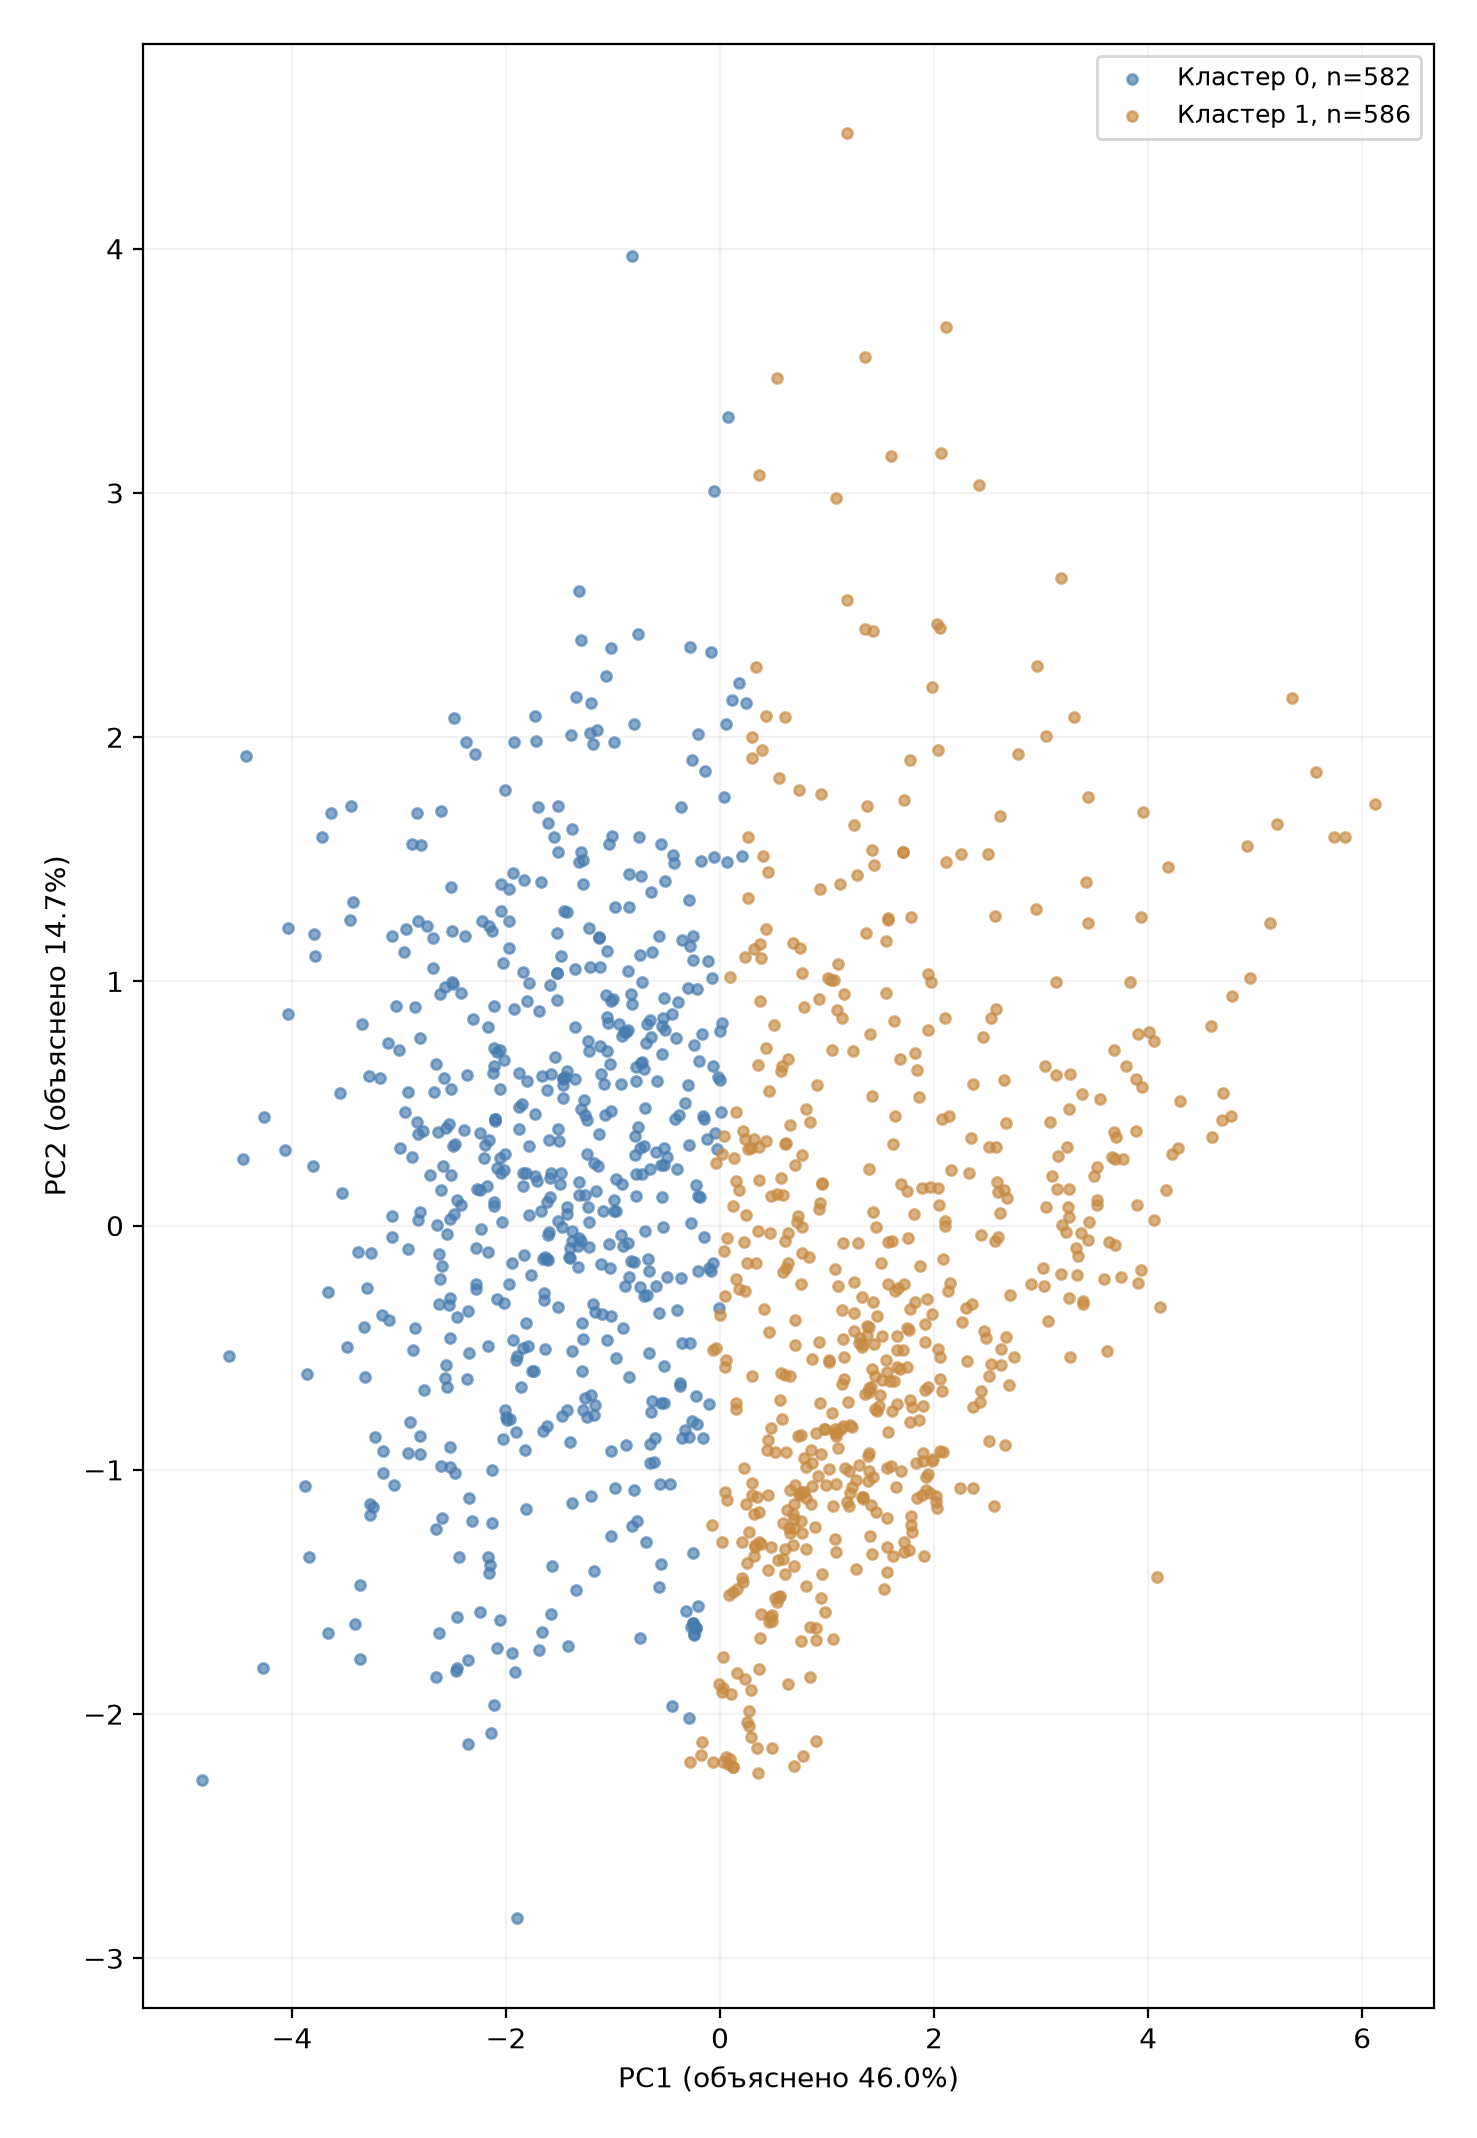

In [5]:
display(Image(filename=str(OUTPUT / "figures" / "6_3_clusters_pca.png"), width=650))

*Рисунок 6.3 — Двумерная PCA-проекция кластеров недвижимости.*

Первые две главные компоненты объясняют **60,7%** вариации восьми подготовленных характеристик. Группы различимы в проекции, однако частично перекрываются. Это согласуется с умеренным значением коэффициента силуэта и не является признаком неправильной работы алгоритма.

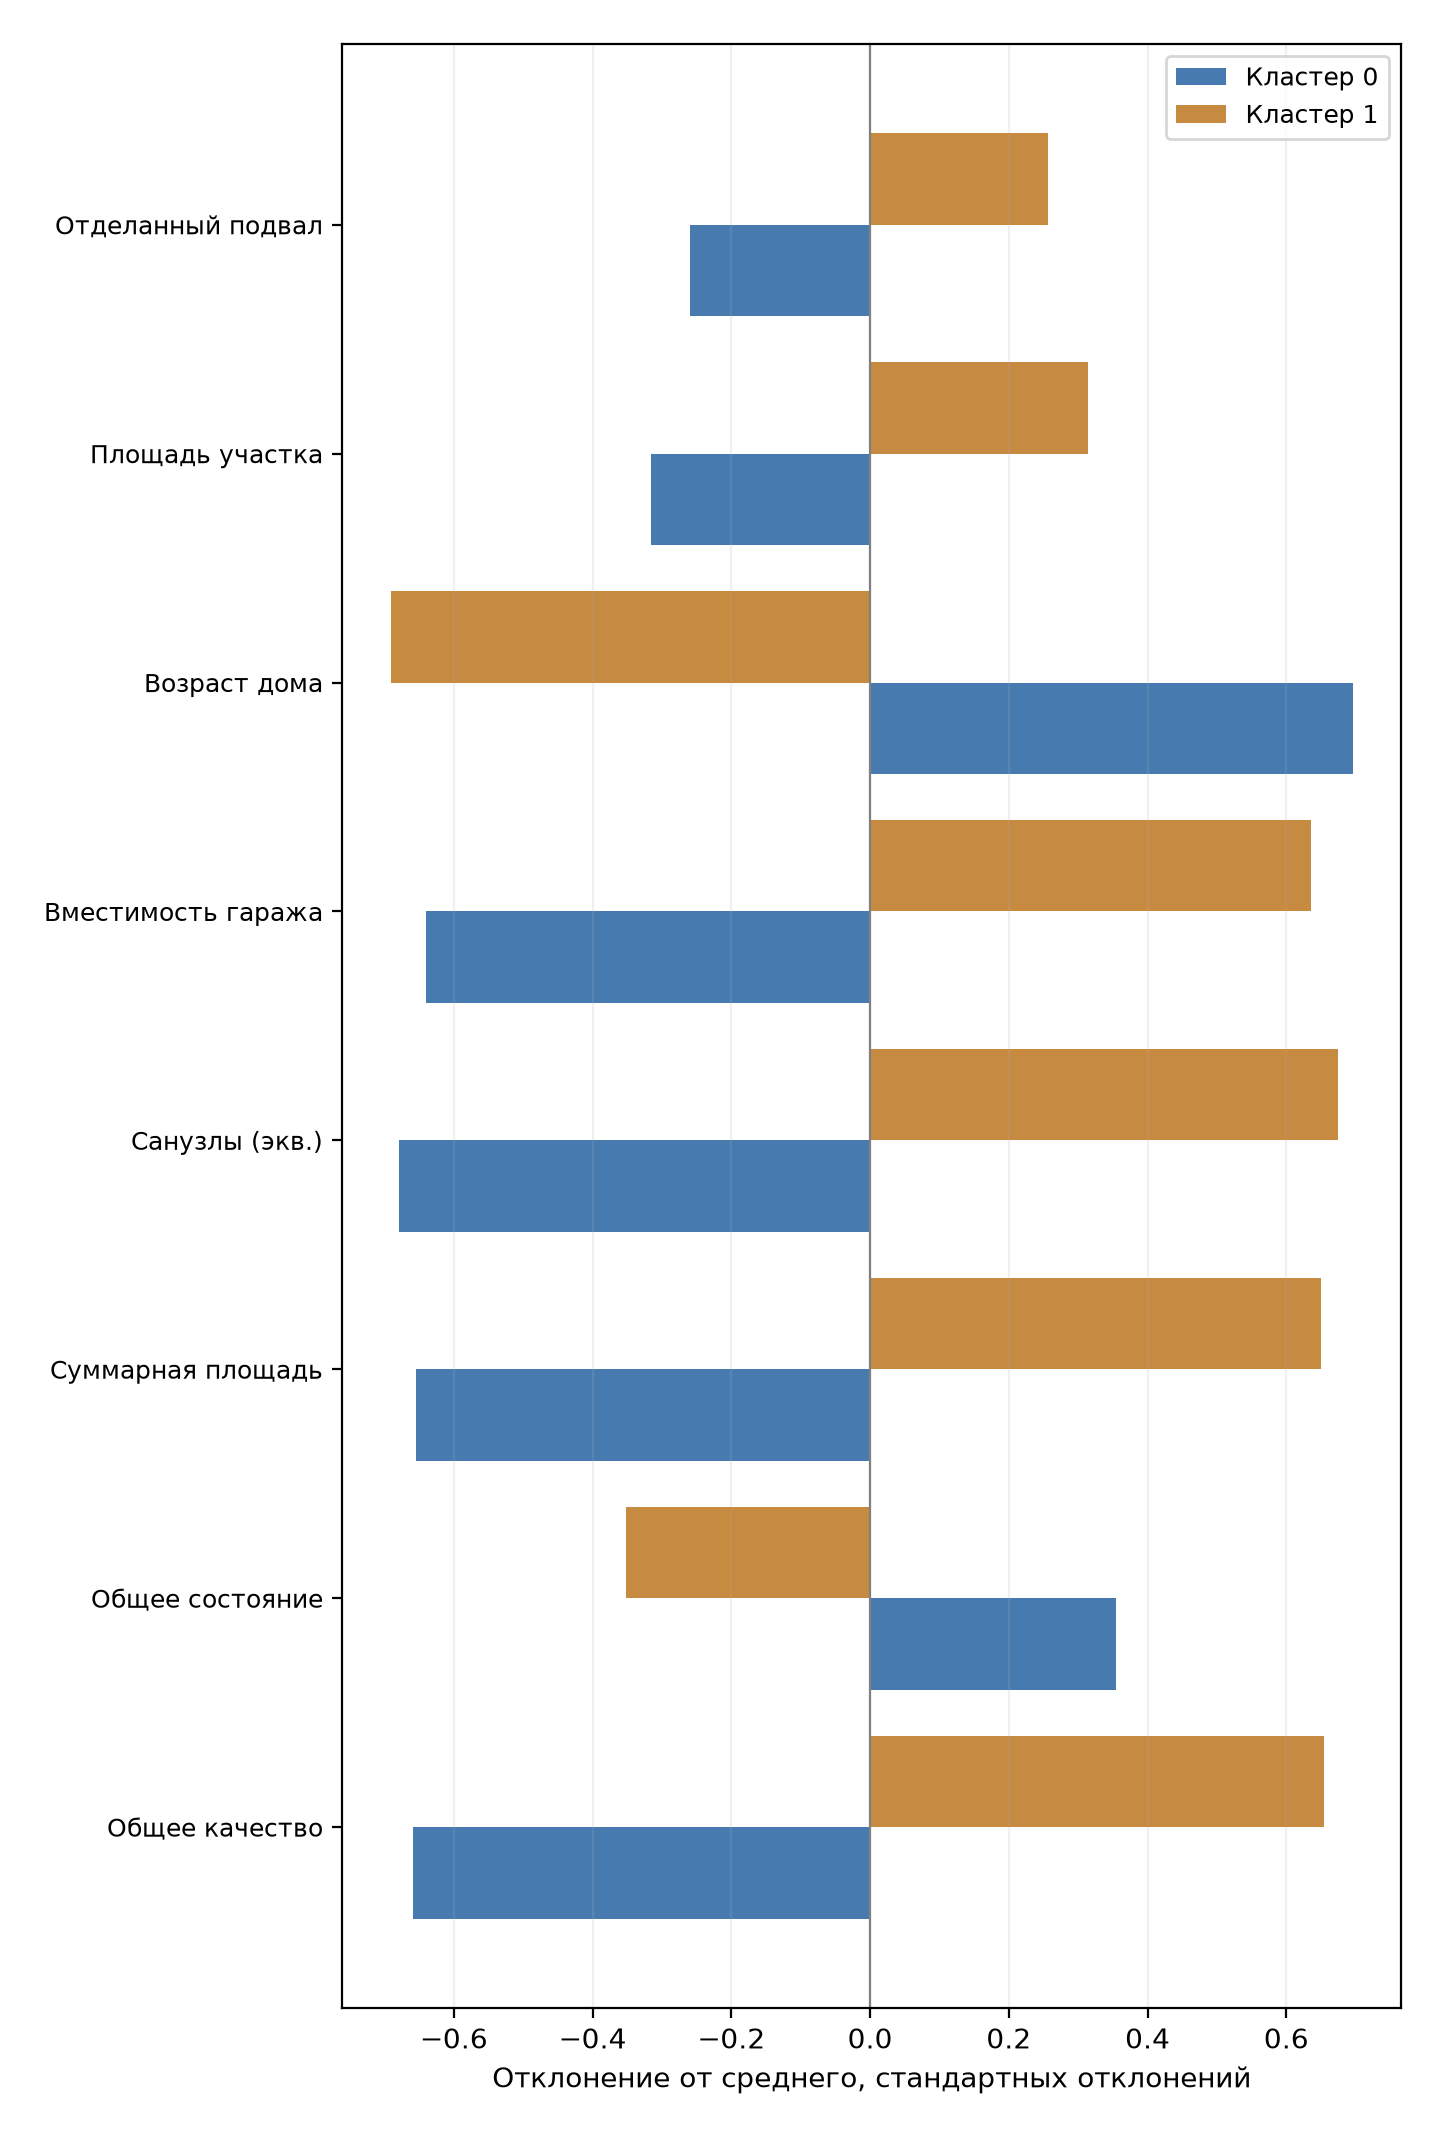

In [6]:
display(Image(filename=str(OUTPUT / "figures" / "6_4_cluster_profiles.png"), width=650))

*Рисунок 6.4 — Сравнение стандартизированных характеристик кластеров.*

На графике показано, чем средние значения признаков внутри групп отличаются от среднего по обучающей выборке. Положительные значения означают превышение общего среднего, отрицательные — значения ниже среднего. Эти отклонения **не являются вкладом в стоимость недвижимости**. Характеристики групп следует читать совместно с таблицей в исходных единицах измерения.

In [7]:
display(features_mean.round(2))

,Cluster,OverallQual,OverallCond,TotalUsefulSF,TotalBathrooms,GarageCars,PropertyAgeAtSale,LotArea,BsmtFinSF1
0,0,5.19,6.0,2060.91,1.68,1.29,57.83,8500.13,331.19
1,1,7.01,5.2,3044.14,2.75,2.24,15.76,10787.00,557.28


По исходным характеристикам **кластер 0** объединяет более старые дома с меньшей суммарной площадью, менее высоким качеством и меньшей вместимостью гаража. **Кластер 1** содержит преимущественно более новые, просторные и качественные объекты. Таким образом, группы имеют содержательные различия, а не только математические номера.

## 4. Сопоставление групп с фактическими ценами

**Только после формирования кластеров** сопоставляем их с ценой продажи и бинарной ценовой категорией. Эти данные не использовались в K-means, поэтому такое сопоставление позволяет независимо описать экономические особенности найденных групп. Оно не является доказательством причинно-следственной связи.

In [8]:
display(profiles.round({
    "MeanPriceUSD": 0,
    "MedianPriceUSD": 0,
    "ExpensiveShare": 4,
    "MeanTotalUsefulSF": 0,
    "MeanOverallQual": 2,
    "MeanAge": 1,
}))

,Cluster,Count,MeanPriceUSD,MedianPriceUSD,ExpensiveShare,MeanTotalUsefulSF,MeanOverallQual,MeanAge
0,0,582,130345.0,131000.0,0.0309,2061.0,5.19,57.8
1,1,586,231729.0,210000.0,0.5631,3044.0,7.01,15.8


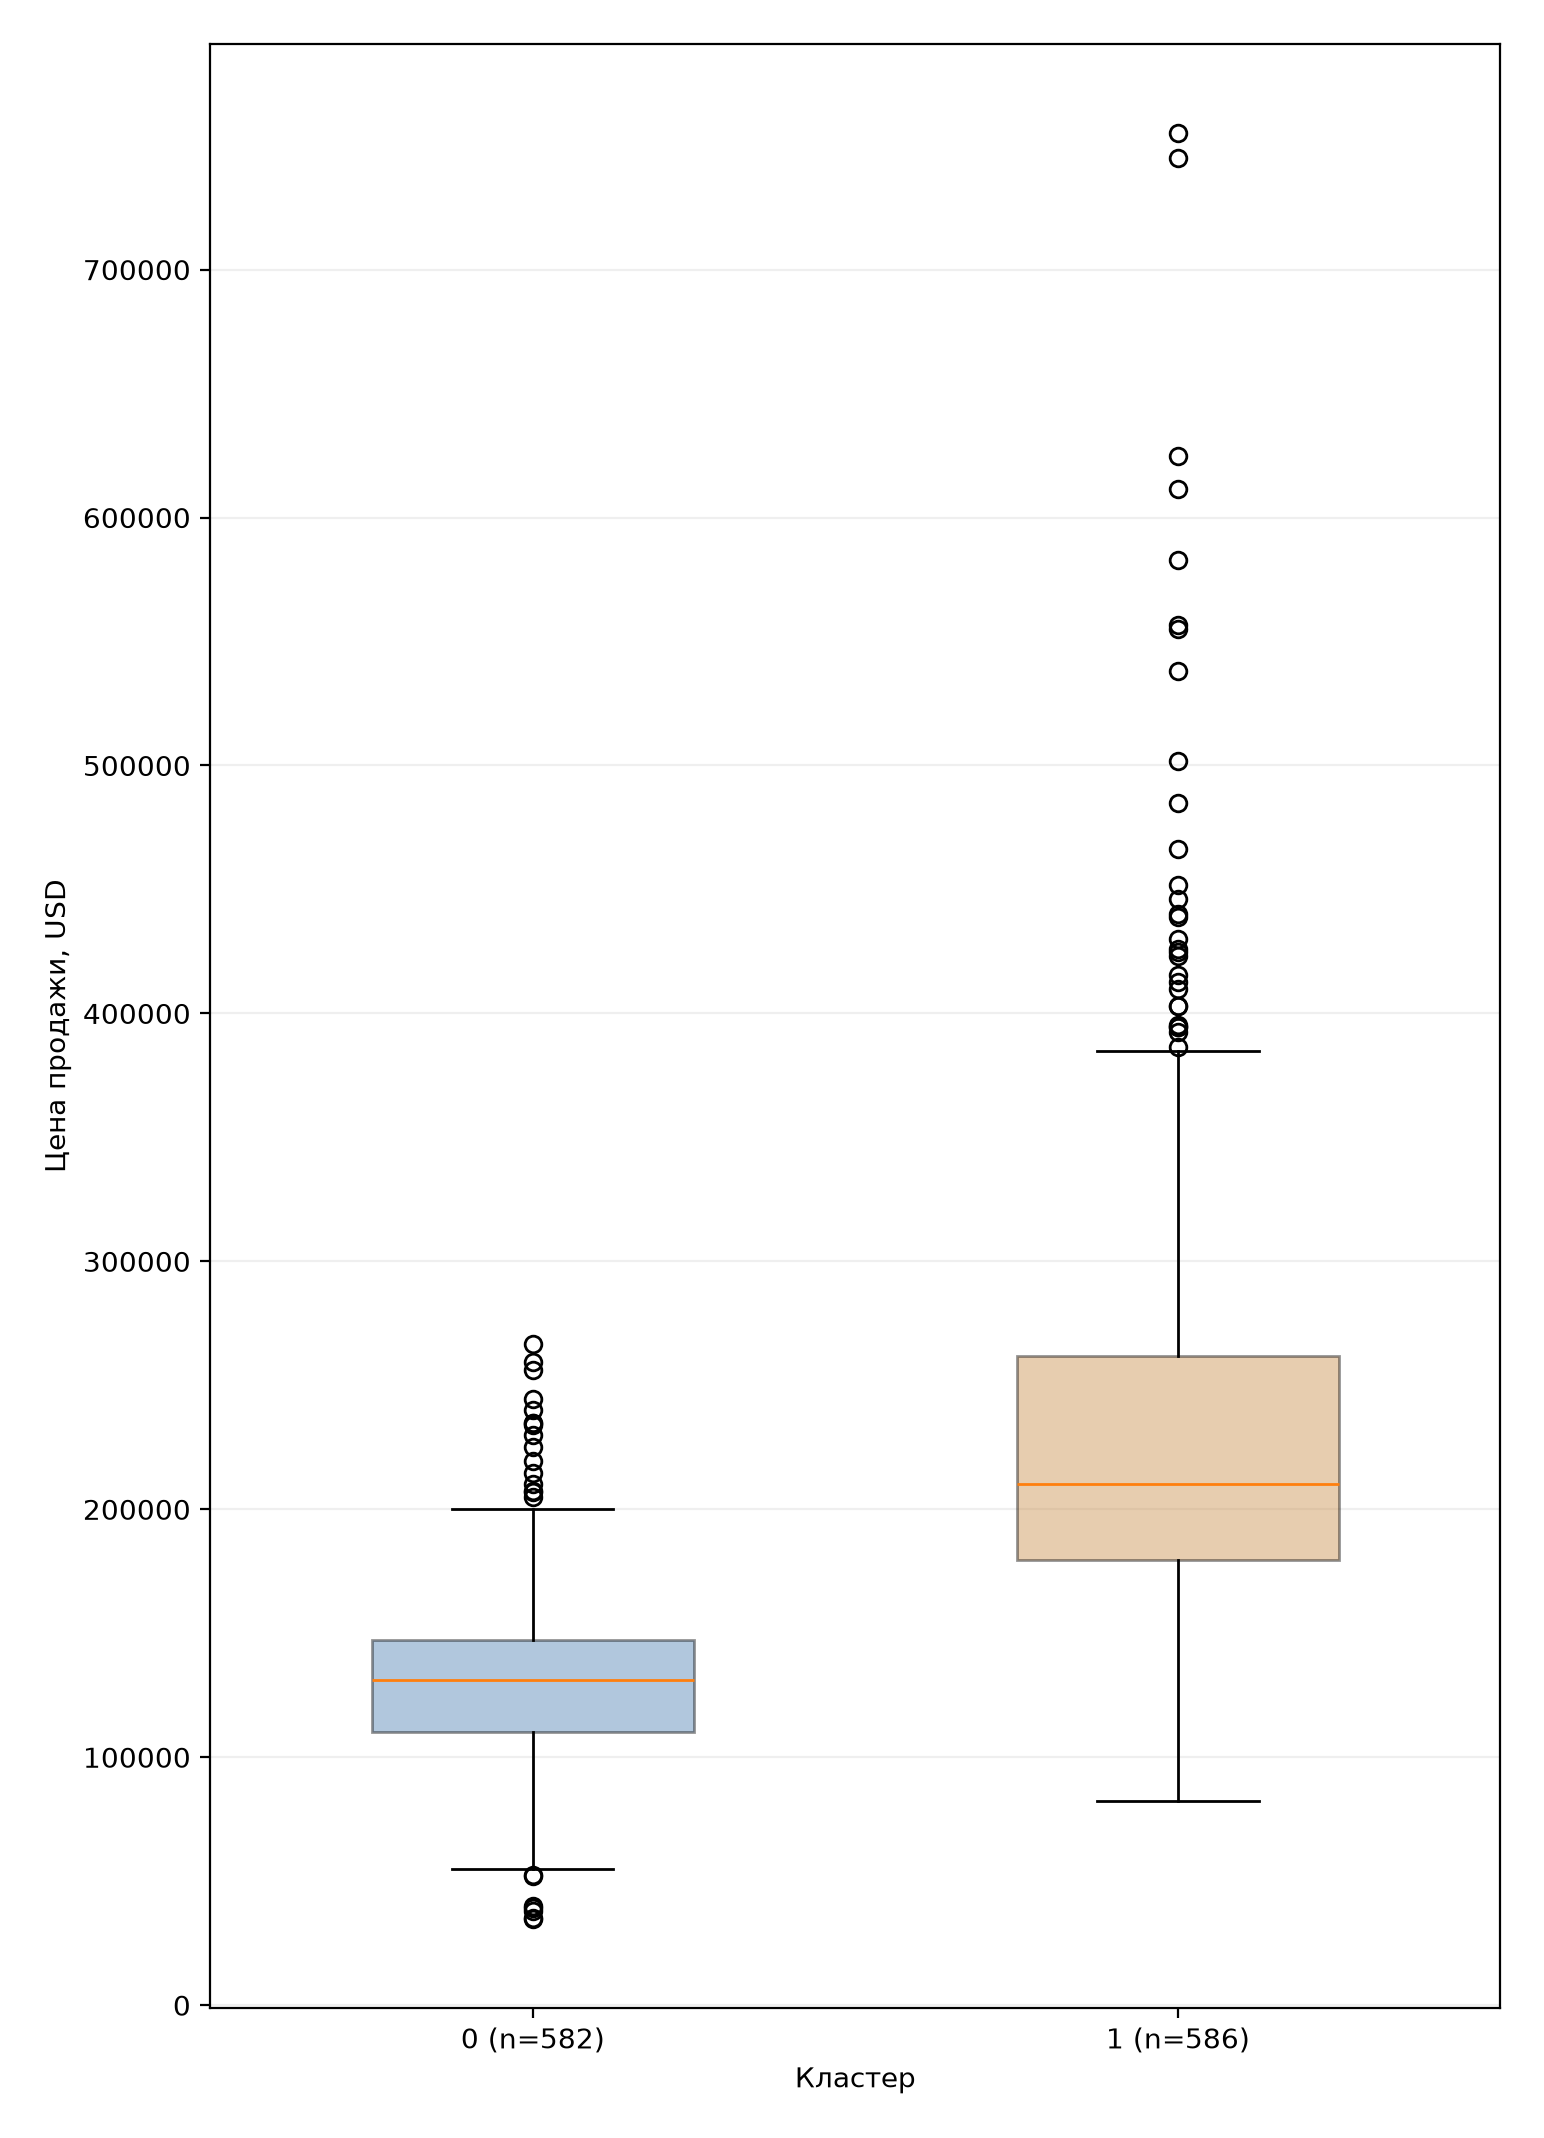

In [9]:
display(Image(filename=str(OUTPUT / "figures" / "6_5_price_by_cluster.png"), width=650))

*Рисунок 6.5 — Распределение стоимости продажи в найденных кластерах.*

В кластере 0 медианная цена равна **$131 000**, средняя — **$130 345**. Для кластера 1 соответствующие значения составляют **$210 000** и **$231 729**. Таким образом, группы, найденные без знания цены, заметно различаются по распределениям стоимости. Диаграммы размаха дополнительно показывают пересечение диапазонов и наличие нетипично дорогих объектов.

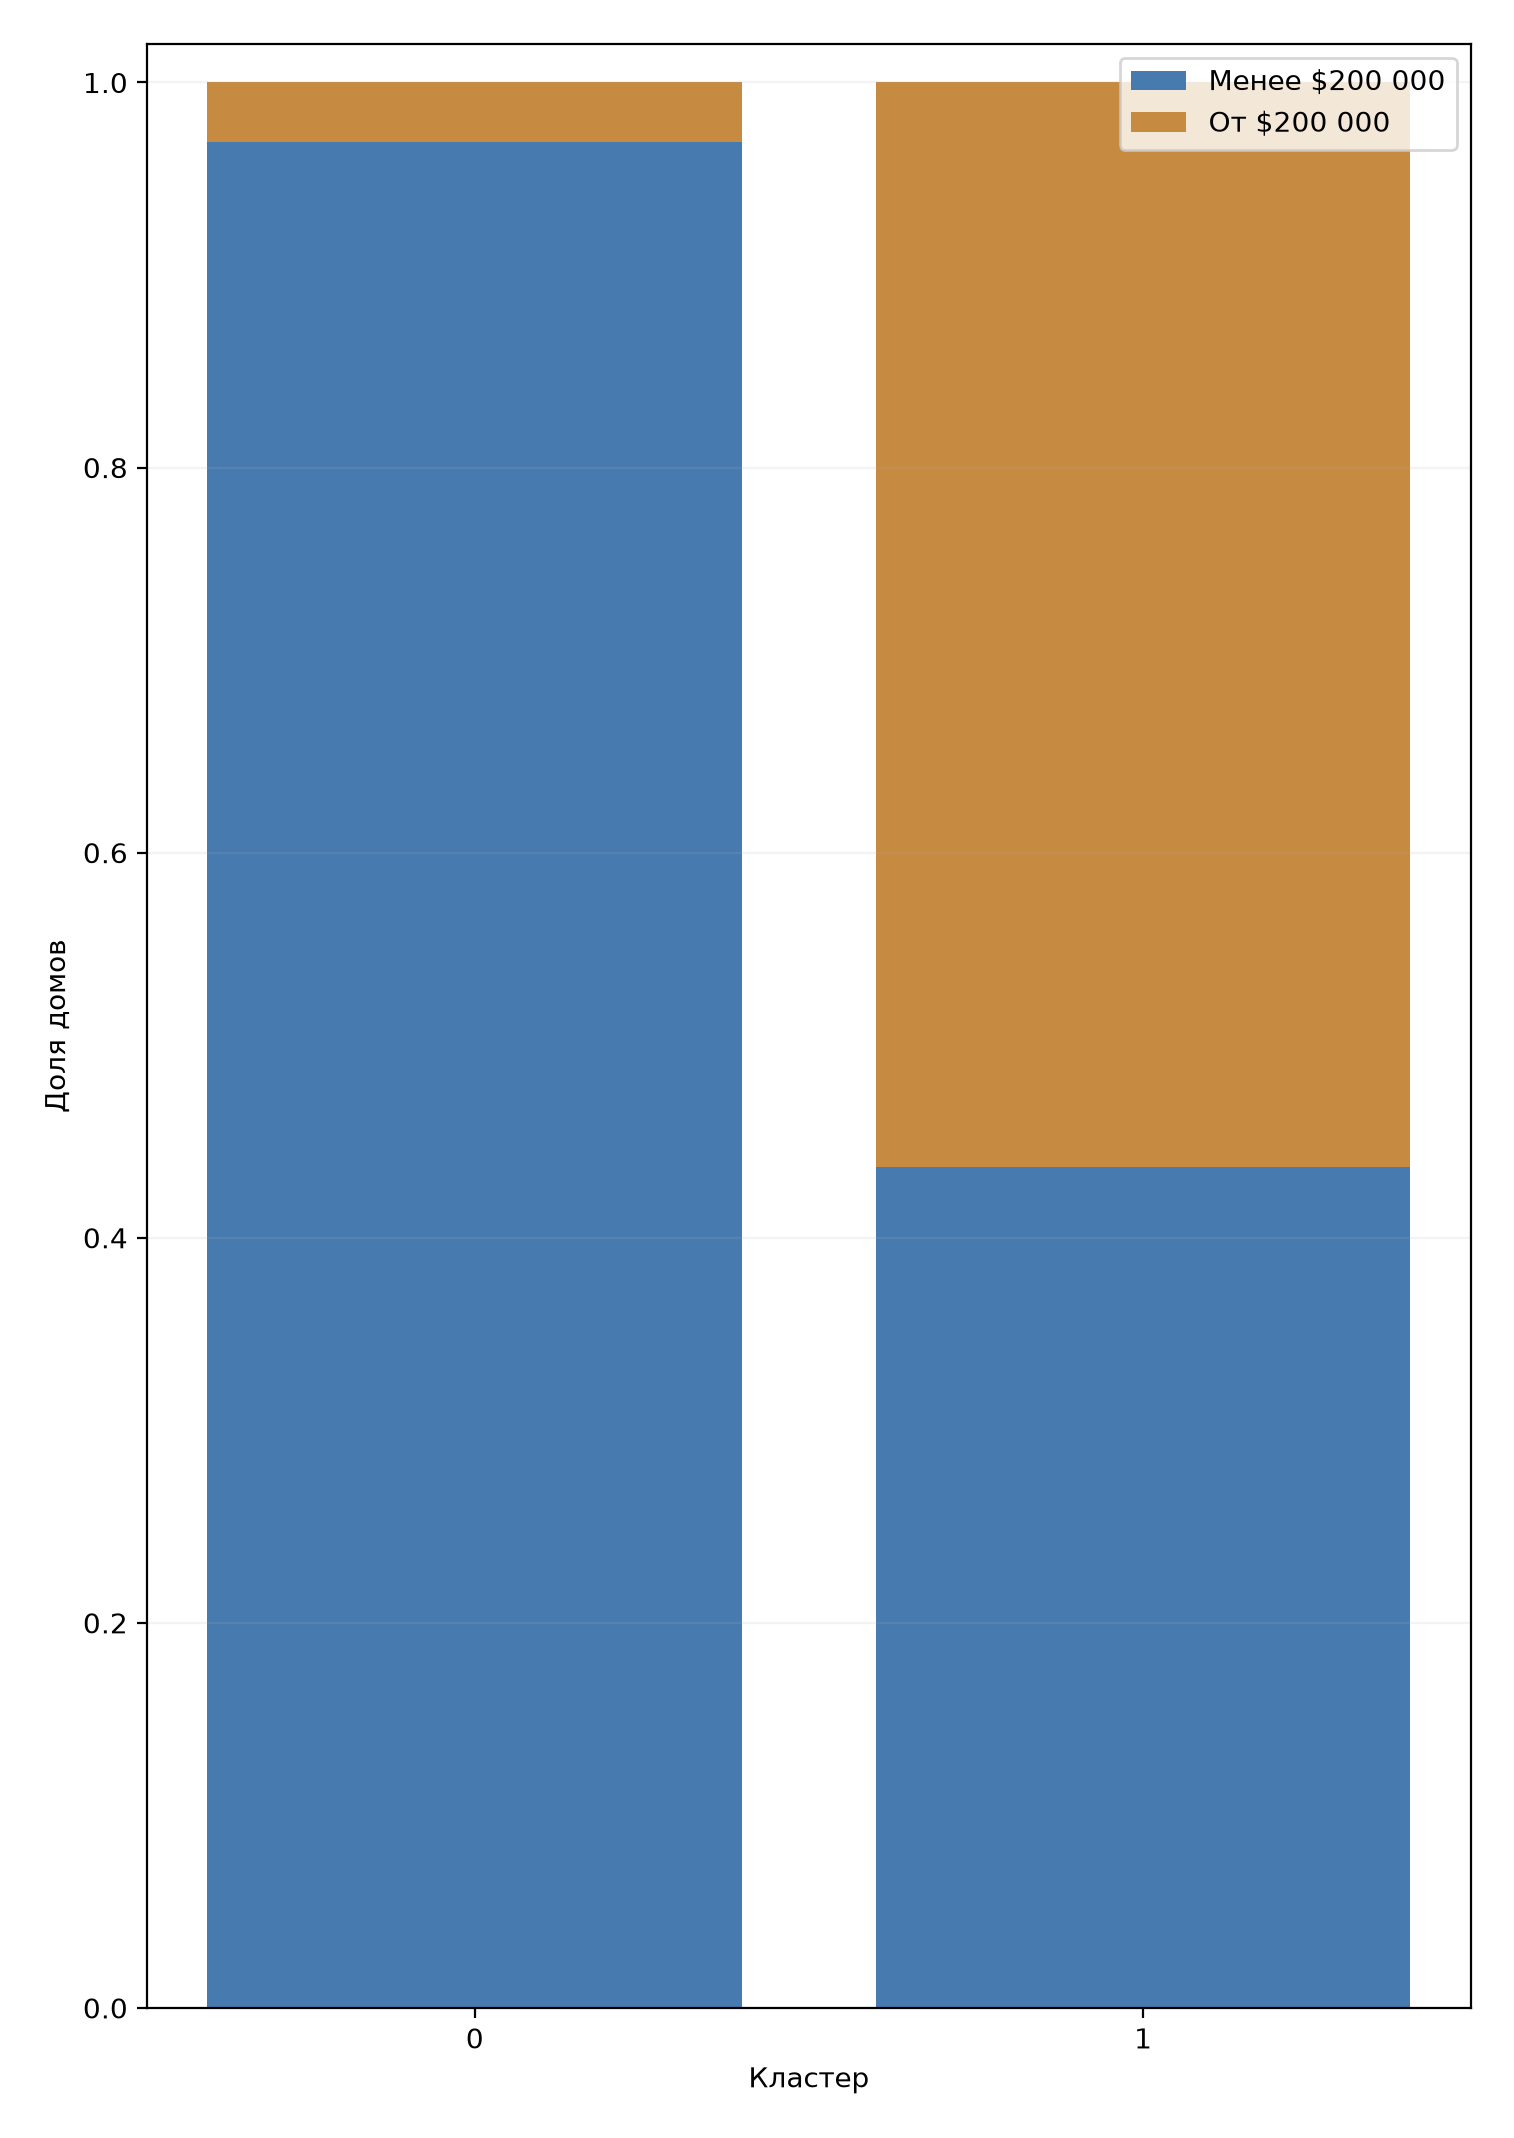

In [10]:
display(Image(filename=str(OUTPUT / "figures" / "6_6_price_classes.png"), width=650))

*Рисунок 6.6 — Доля домов разных ценовых сегментов внутри кластеров.*

Доля объектов со стоимостью от $200 000 составляет **3,1%** в кластере 0 и **56,3%** в кластере 1. Поскольку каждый столбец нормирован до 100%, сравнение не зависит от небольшой разницы в численности групп (582 и 586 домов).

Сопоставление рисунков 6.5 и 6.6 показывает, что более новые и просторные дома чаще относятся к дорогому ценовому сегменту. Однако разбиение на кластеры **не равно бинарной классификации по цене**: во втором кластере остаётся значительная доля домов дешевле $200 000.

## 5. Дополнительная проверка структуры: t-SNE и DBSCAN

t-SNE (стохастическое вложение соседей) используется для дополнительной двумерной визуализации локальных соседств. DBSCAN (кластеризация по плотности) ищет плотные группы и может отмечать нетипичные наблюдения как шум (`-1`). Эти методы работают по другим принципам, поэтому их результаты нельзя непосредственно приравнивать к K-means.

Следующие изображения создаются при запуске `python main.py clustering --tsne --dbscan`.

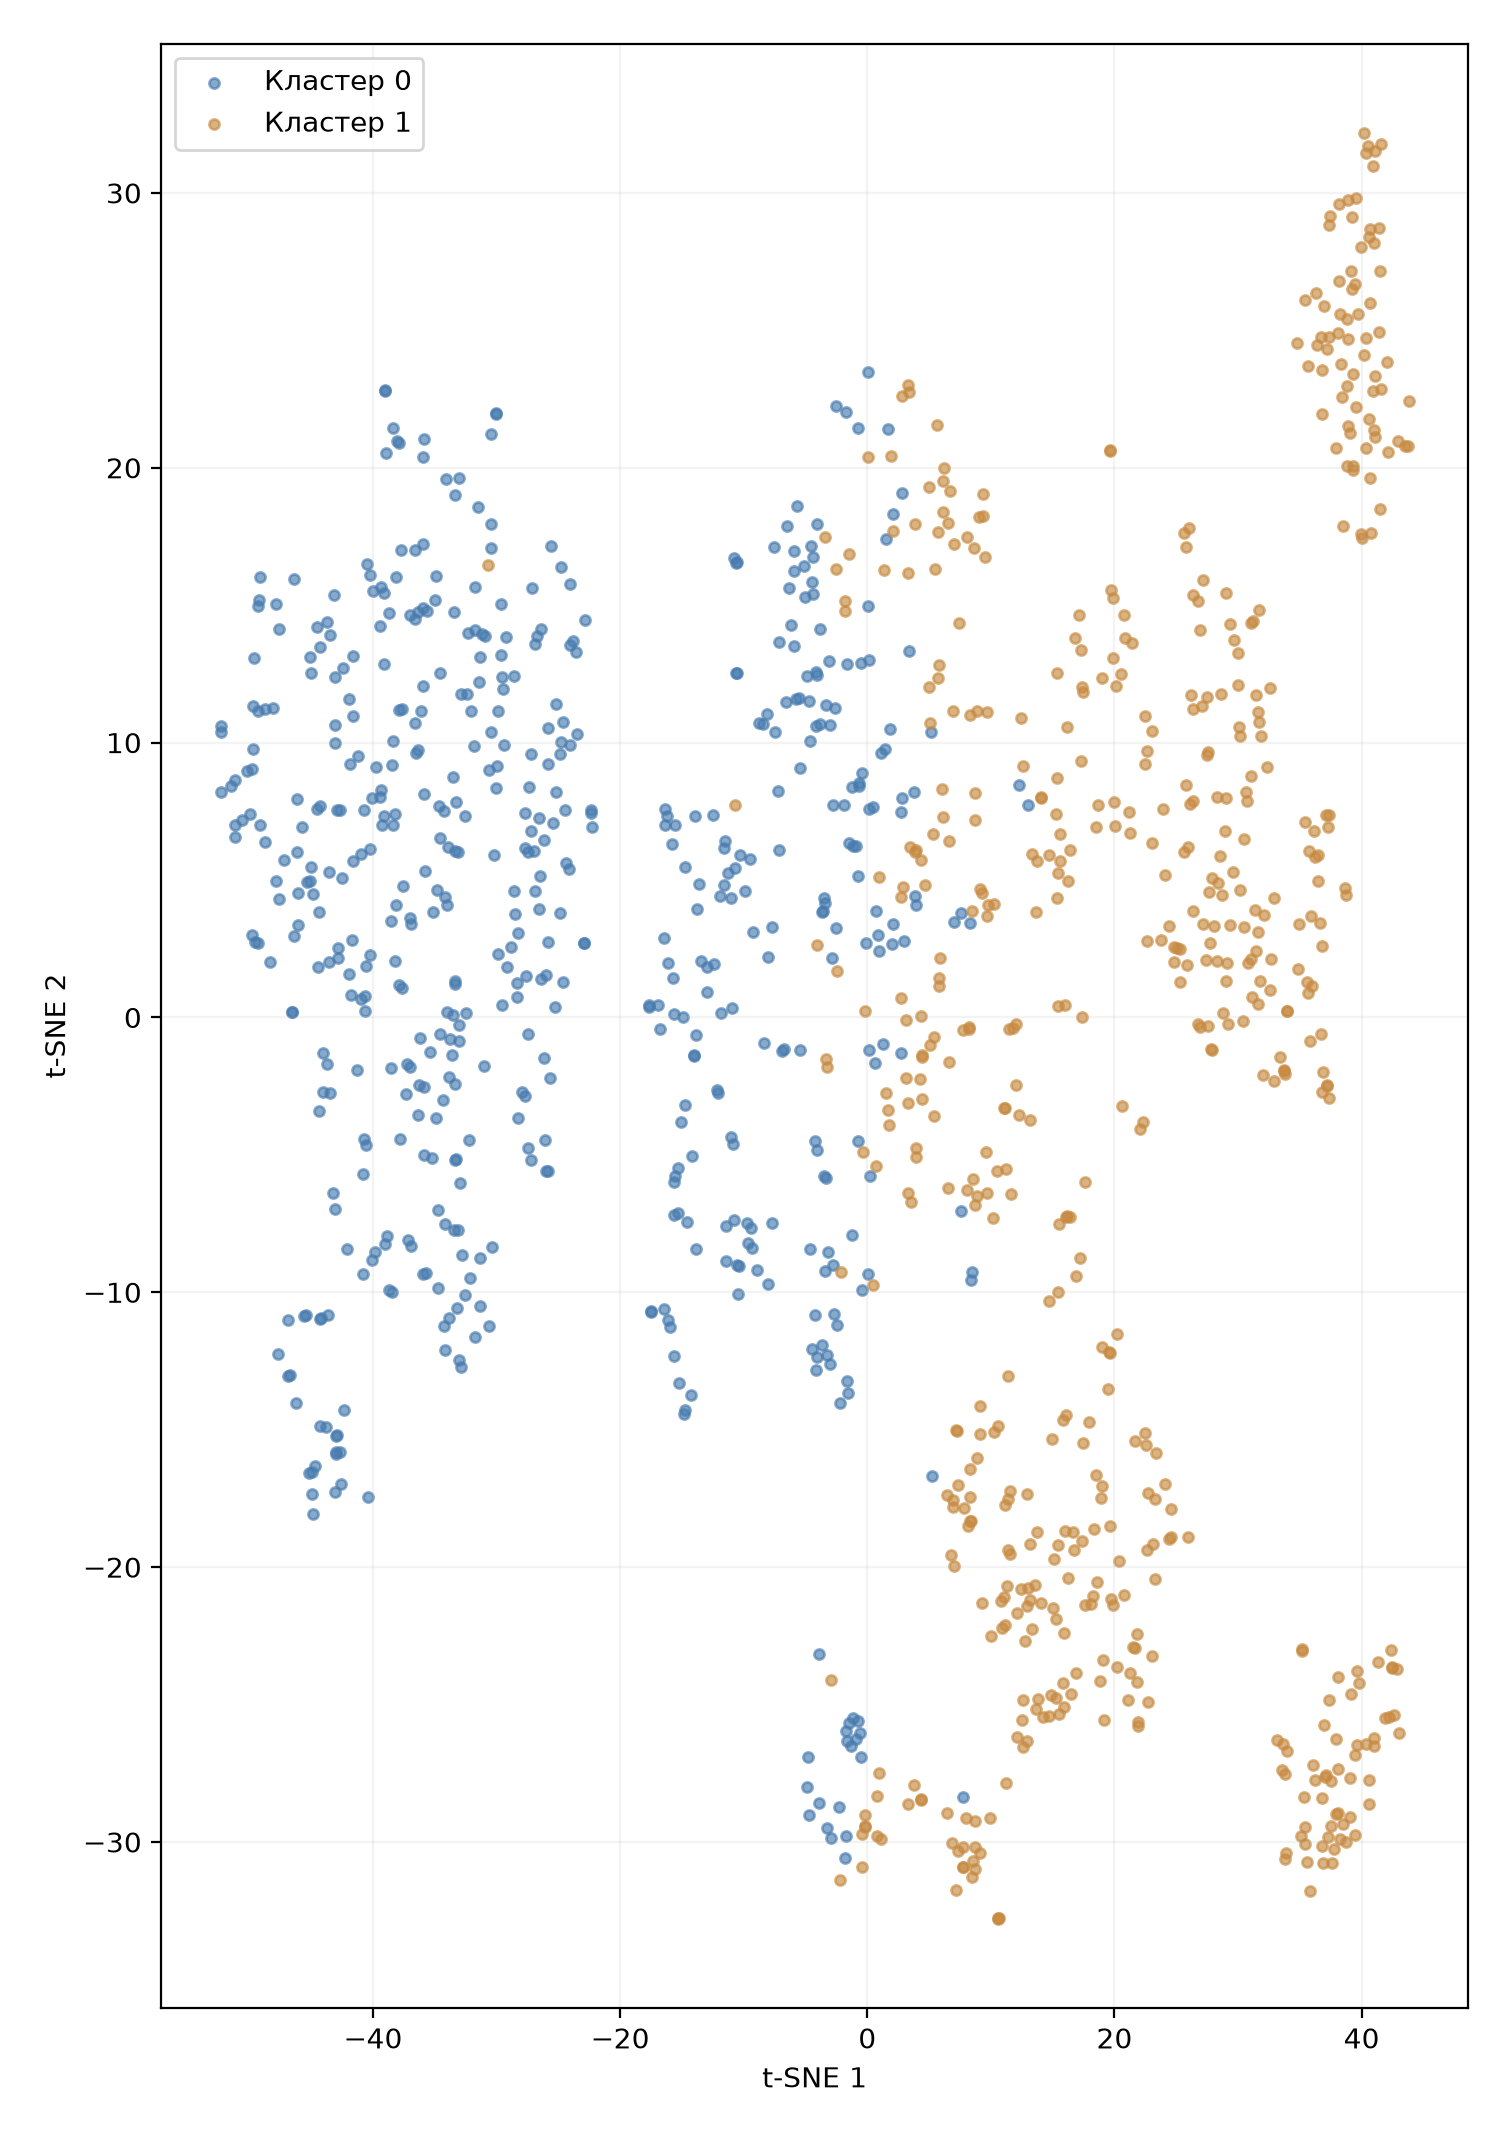

*Рисунок 6.7 — t-SNE-проекция кластеров K-means.*

In [11]:
tsne_path = OUTPUT / "figures" / "6_7_clusters_tsne.png"
if tsne_path.is_file():
    display(Image(filename=str(tsne_path), width=650))
    display(Markdown("*Рисунок 6.7 — t-SNE-проекция кластеров K-means.*"))
else:
    print("Рисунок 6.7 не создан: используйте параметр --tsne.")

На t-SNE отображается локальная структура соседств домов, найденных в восьмимерном пространстве. Форма и расстояние между отдельными визуальными «островами» сами по себе не доказывают качество кластеров. Поэтому вывод о предпочтительном k основан на исходных стандартизированных признаках, а не на t-SNE-проекции.

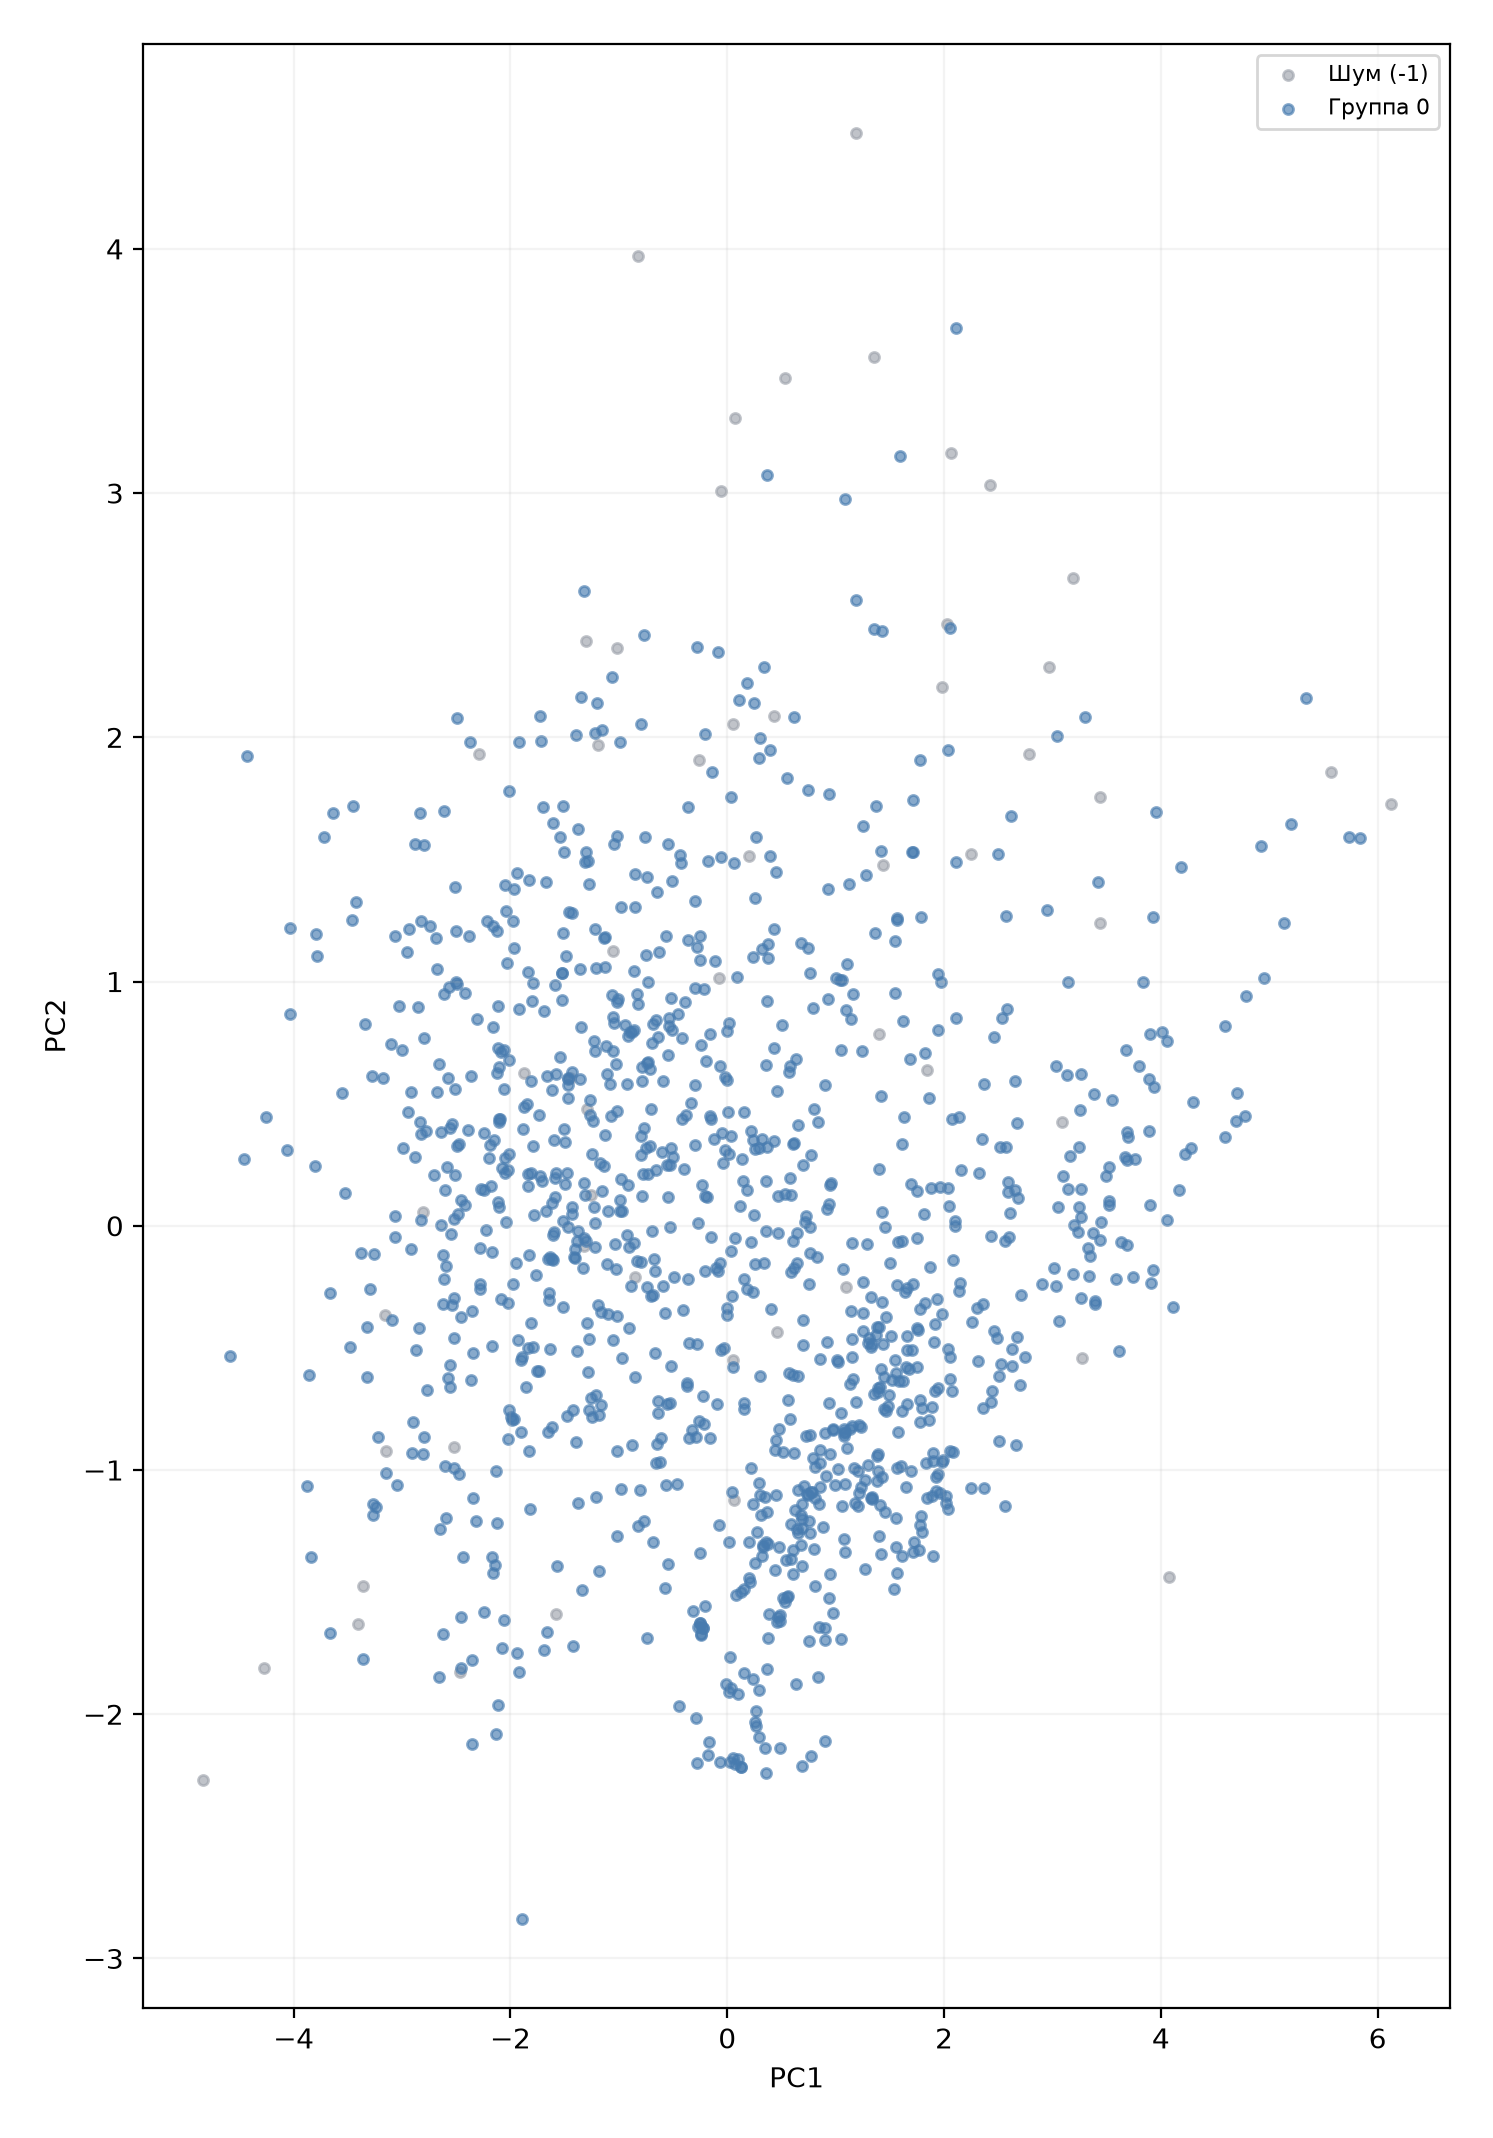

*Рисунок 6.8 — Результат DBSCAN в PCA-проекции.*

In [12]:
dbscan_path = OUTPUT / "figures" / "6_8_dbscan_pca.png"
if dbscan_path.is_file():
    display(Image(filename=str(dbscan_path), width=650))
    display(Markdown("*Рисунок 6.8 — Результат DBSCAN в PCA-проекции.*"))
else:
    print("Рисунок 6.8 не создан: используйте параметр --dbscan.")

В дополнительных расчётах DBSCAN при `eps = 1,8` и `min_samples = 10` выделил **одну плотностную группу**, отнеся около **4,6%** наблюдений к шуму. Значение параметров не оптимизировалось, поэтому этот результат следует интерпретировать как ограниченный сравнительный эксперимент, а не как отрицательный вывод о применимости DBSCAN вообще.

## Итоговые выводы

В ходе исследования проведена кластеризация **1 168 исторических объектов недвижимости** по восьми содержательно выбранным и стандартизированным характеристикам. Фактическая стоимость, идентификатор и бинарный ценовой сегмент не участвовали в формировании групп. Количество кластеров K-means определено по коэффициенту силуэта среди значений `k = 2…8` с требованием минимальной численности каждой группы.

Наиболее предпочтительным вариантом оказалось **k = 2** при коэффициенте силуэта **0,2652**. Обнаруженные группы имеют близкую численность — **582** и **586** объектов. Невысокое значение силуэта указывает на ограниченную геометрическую разделимость и частичное перекрытие кластеров. Две компоненты PCA сохранили **60,7%** вариации исследуемых характеристик, поэтому визуальная проекция не исчерпывает многомерную структуру данных.

**Кластер 0** характеризуется более старой недвижимостью (средний возраст **57,8 года**), меньшей суммарной площадью (около **2 061 кв. фута**) и более низким уровнем качества (в среднем **5,19 балла**). В **кластере 1** средний возраст составляет **15,8 года**, суммарная площадь — около **3 044 кв. футов**, а качество — **7,01 балла**. Полученные различия позволяют интерпретировать кластеры как условные группы более старого и компактного жилья и более нового и просторного жилья.

Последующее, независимое от процедуры кластеризации сопоставление с ценами выявило существенную разницу: медианная стоимость составляет **$131 000** и **$210 000**, доля объектов стоимостью от **$200 000** — **3,1%** и **56,3%** соответственно. Тем самым найдена содержательно интерпретируемая связь кластерной структуры с ценовыми характеристиками. Вместе с тем группы не совпадают полностью с ценовыми сегментами, а установленные различия носят описательный, а не причинный характер.

Дополнительная визуализация t-SNE подтверждает возможность представить локальные соседства объектов в двух измерениях. DBSCAN при выбранных параметрах сформировал одну группу и пометил около **4,6%** объектов как шум. Этот результат не является основанием для окончательного сравнения алгоритмов, поскольку настройки DBSCAN отдельно не оптимизировались.

**Практический вывод:** разделение недвижимости по ограниченному набору характеристик может использоваться для описательной сегментации, предварительного изучения групп и исследования нетипичных объектов. Однако полученные результаты **не подтверждают автоматически повышение точности регрессионных или классификационных моделей**. Проверка такой гипотезы потребовала бы отдельного сравнительного эксперимента, где предобработка и назначение кластеров выполняются только на обучающей части каждого валидационного разбиения.

Ограничениями исследования остаются выбор восьми признаков, евклидова метрика, способ стандартизации, обработка выбросов и умеренная разделимость групп. В последующей работе возможны сравнение других наборов характеристик, подбор параметров плотностных методов и проверка устойчивости кластеров при изменении исходной выборки.